# Transformers


#### A Transformer is a deep learning architecture designed to process sequences of text using self-attention.

- Transformers are the foundation of many modern NLP models, including BERT, GPT, and T5.

- Before Transformers, we used models such as RNNs and LSTMs for NLP tasks.

<img src="https://drive.google.com/thumbnail?id=1unPqGaKftHxp37-F99Bg6hJzFbQdCGC7&sz=w1000" width="700">

In [ ]:
%pip -q install transformers torch matplotlib

## 1. Load a Transformer

We use **DistilBERT**, a  Transformer fine-tuned for positive/negative sentiment classification.

In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch

model_name = "distilbert-base-uncased-finetuned-sst-2-english"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForSequenceClassification.from_pretrained(model_name)
model.eval()

# Look inside the Transformer architecture.
print("Transformer layers:", model.config.n_layers)
print("Attention heads per layer:", model.config.n_heads)
print("Hidden size:", model.config.dim)

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Transformer layers: 6
Attention heads per layer: 12
Hidden size: 768



<img src="https://drive.google.com/thumbnail?id=1v2dRK1KR_ydZOknjj8Xv8_wjOdXleDYs&sz=w1000" width="500">

## 2. Tokenizing the text

In [ ]:
sentence = "The movie was not good."

# Tokenization: converts text into token IDs
inputs = tokenizer(sentence, return_tensors="pt")

# [CLS] = start token, [SEP] = end token
tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

print("Tokens:", tokens)

Tokens: ['[CLS]', 'the', 'movie', 'was', 'not', 'good', '.', '[SEP]']


## 3. Embeddings and self-attention

Each token ID becomes a **vector (embedding)**. Inside each Transformer layer, **self-attention** lets a token use information from other tokens in the same sentence.

In [ ]:
import torch

# Enable attention weights
model.set_attn_implementation("eager")

with torch.no_grad():
    embeddings = model.distilbert.embeddings(inputs["input_ids"])
    outputs = model(**inputs, output_attentions=True)

# Attention from the first layer and first head
attention = outputs.attentions[0][0, 0]

print("Embeddings shape:", embeddings.shape)
print("Attention shape:", attention.shape)
print("Tokens:", tokens)
print("Attention weights:\n", attention)

Embeddings shape: torch.Size([1, 8, 768])
Attention shape: torch.Size([8, 8])
Tokens: ['[CLS]', 'the', 'movie', 'was', 'not', 'good', '.', '[SEP]']
Attention weights:
 tensor([[0.1145, 0.0938, 0.0681, 0.0701, 0.0596, 0.0800, 0.1593, 0.3546],
        [0.4147, 0.0793, 0.0481, 0.1018, 0.1084, 0.0805, 0.0789, 0.0883],
        [0.1634, 0.0327, 0.0975, 0.0403, 0.1819, 0.1402, 0.0866, 0.2574],
        [0.2882, 0.1014, 0.0504, 0.0669, 0.2180, 0.1009, 0.1231, 0.0511],
        [0.3612, 0.0501, 0.0696, 0.1200, 0.0642, 0.1304, 0.0953, 0.1092],
        [0.3065, 0.0469, 0.1175, 0.1915, 0.0630, 0.0555, 0.1120, 0.1071],
        [0.3505, 0.0935, 0.0572, 0.0753, 0.0972, 0.0964, 0.1165, 0.1135],
        [0.3513, 0.1019, 0.0318, 0.0541, 0.1036, 0.0607, 0.0755, 0.2210]])


## 4. Classification: From Transformer to prediction

The Transformer produces contextual representations. The **classification head** turns them into two scores (*logits*). **Softmax** converts these into probabilities that sum to 1.

In [ ]:
# Get prediction scores from the Transformer
with torch.no_grad():
    logits = model(**inputs).logits

# Convert scores into probabilities
probs = torch.softmax(logits, dim=1)[0]

# Display the prediction
prediction = probs.argmax().item()

print("Prediction:", model.config.id2label[prediction])
print("Confidence:", round(probs[prediction].item(), 3))


Prediction: NEGATIVE
Confidence: 1.0



### Task: Exploring Transformer Layers and Attention Heads

Load the pretrained **`bert-base-uncased`** model using Hugging Face Transformers.

1. Write code to print the number of Transformer layers and the number of attention heads per layer.
2. Calculate and print the total number of attention heads across all Transformer layers.
3. Using the sentence `"Transformers use self-attention to understand language."`, extract the attention weights from the **third Transformer layer and second attention head**.
4. Explain what the rows and columns of the attention matrix represent.

## Task Solution

### 1. Load `bert-base-uncased` and print the number of layers and attention heads

In [ ]:
from transformers import AutoTokenizer, AutoModel
import torch

bert_name = "bert-base-uncased"

bert_tokenizer = AutoTokenizer.from_pretrained(bert_name)

# "eager" attention is needed so the model can return its attention weights
bert_model = AutoModel.from_pretrained(bert_name, attn_implementation="eager")
bert_model.eval()

# BERT stores these values under different names than DistilBERT (n_layers / n_heads)
num_layers = bert_model.config.num_hidden_layers
num_heads = bert_model.config.num_attention_heads

print("Transformer layers:", num_layers)
print("Attention heads per layer:", num_heads)
print("Hidden size:", bert_model.config.hidden_size)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Transformer layers: 12
Attention heads per layer: 12
Hidden size: 768


### 2. Total number of attention heads across all layers

Every layer has the same number of heads, so the total is **layers × heads per layer**.

In [ ]:
total_heads = num_layers * num_heads

print(f"Total attention heads: {num_layers} x {num_heads} = {total_heads}")

Total attention heads: 12 x 12 = 144


### 3. Attention weights from the third layer and second attention head

Python counts from 0, so the **third layer** is index `2` and the **second head** is index `1`.

`outputs.attentions` is a tuple with one tensor per layer. Each tensor has the shape `[batch, heads, tokens, tokens]`.

In [ ]:
import pandas as pd

sentence = "Transformers use self-attention to understand language."

bert_inputs = bert_tokenizer(sentence, return_tensors="pt")
bert_tokens = bert_tokenizer.convert_ids_to_tokens(bert_inputs["input_ids"][0])

with torch.no_grad():
    bert_outputs = bert_model(**bert_inputs, output_attentions=True)

print("Number of layers returned:", len(bert_outputs.attentions))
print("Shape of one layer's attention:", bert_outputs.attentions[0].shape)

# Third layer (index 2), first sentence in the batch (index 0), second head (index 1)
layer_index = 2
head_index = 1
attention_matrix = bert_outputs.attentions[layer_index][0, head_index]

print("Tokens:", bert_tokens)
print("Attention matrix shape:", attention_matrix.shape)

# Show the matrix as a table with the tokens as row and column labels
pd.DataFrame(attention_matrix.numpy(), index=bert_tokens, columns=bert_tokens).round(3)

Number of layers returned: 12
Shape of one layer's attention: torch.Size([1, 12, 11, 11])
Tokens: ['[CLS]', 'transformers', 'use', 'self', '-', 'attention', 'to', 'understand', 'language', '.', '[SEP]']
Attention matrix shape: torch.Size([11, 11])


,[CLS],transformers,use,self,-,attention,to,understand,language,.,[SEP]
[CLS],0.732,0.008,0.011,0.006,0.017,0.007,0.010,0.012,0.006,0.039,0.155
transformers,0.889,0.005,0.034,0.000,0.003,0.005,0.001,0.001,0.000,0.005,0.057
use,0.143,0.569,0.005,0.035,0.041,0.068,0.090,0.000,0.005,0.009,0.034
self,0.340,0.073,0.002,0.000,0.202,0.081,0.064,0.026,0.002,0.028,0.183
-,0.143,0.070,0.071,0.639,0.012,0.013,0.003,0.003,0.014,0.009,0.022
attention,0.113,0.545,0.012,0.020,0.111,0.010,0.072,0.000,0.000,0.016,0.100
to,0.084,0.022,0.622,0.008,0.009,0.194,0.011,0.007,0.001,0.014,0.027
understand,0.434,0.005,0.002,0.022,0.012,0.003,0.330,0.002,0.055,0.053,0.082
language,0.051,0.001,0.429,0.002,0.004,0.001,0.005,0.398,0.006,0.041,0.062
.,0.658,0.006,0.003,0.001,0.004,0.003,0.009,0.038,0.046,0.073,0.159


In [ ]:
# Each row is a softmax output, so every row should add up to 1
print("Row sums:", attention_matrix.sum(dim=1).round(decimals=3))

Row sums: tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])


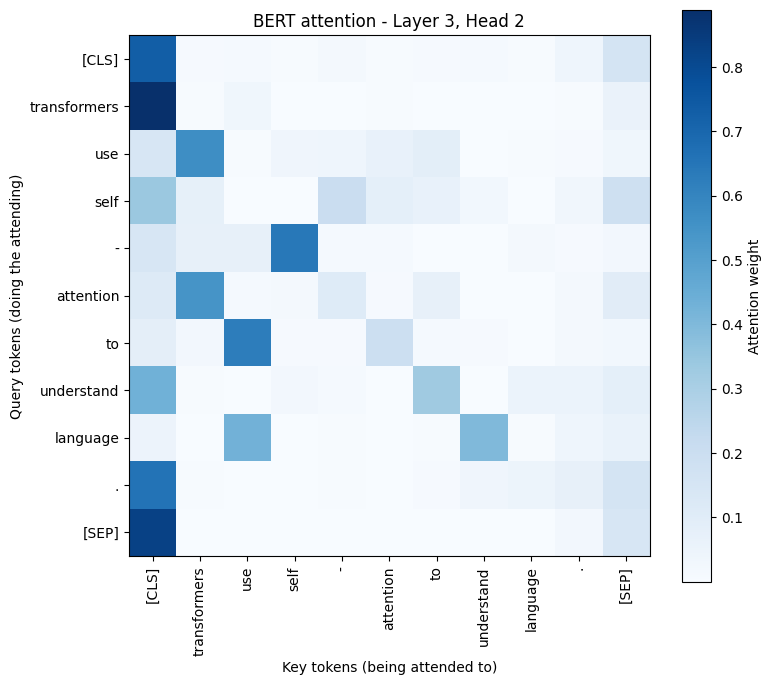

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 7))
plt.imshow(attention_matrix.numpy(), cmap="Blues")
plt.xticks(range(len(bert_tokens)), bert_tokens, rotation=90)
plt.yticks(range(len(bert_tokens)), bert_tokens)
plt.xlabel("Key tokens (being attended to)")
plt.ylabel("Query tokens (doing the attending)")
plt.title("BERT attention - Layer 3, Head 2")
plt.colorbar(label="Attention weight")
plt.tight_layout()
plt.show()

### 4. What do the rows and columns of the attention matrix represent?

The matrix is square, with one row and one column for every token in the sentence, including `[CLS]` and `[SEP]`.

- **Rows are the query tokens.** Row *i* belongs to the token that is "looking" at the sentence to update its own representation.
- **Columns are the key tokens.** Column *j* belongs to the token that is being looked at.
- **Cell [i, j]** is how much token *i* pays attention to token *j* in this head: how much of token *j*'s information goes into token *i*'s new representation in layer 3.
- **Each row adds up to 1**, because the weights come from a softmax. A row is a probability distribution showing how token *i* spreads its attention over all the tokens in the sentence (itself included).
- The matrix is usually **not symmetric**. Token *i* can pay a lot of attention to token *j* while *j* pays little attention to *i*.

Each head learns its own pattern. Some heads focus on the next or previous word, some link related words (for example a verb and its object), and many put a large weight on `[CLS]` or `[SEP]` when there is nothing useful to attend to. Looking at a single head shows only one of the 144 patterns BERT combines to understand the sentence.